# Lab 28-09 · Translating Area, Power and Time into Money

Companion to [chapter 28-09](../../chapters/28-09-business-engineering-translation.md). Every part asks you to **predict first**, then run. Wafer prices are reported estimates [R-575]; other parameters are assumptions.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, '.')
import translate as tr

## Part 1 · Cost against area

**Predict:** the elasticity of die cost to area at 600 mm².

elasticity at 100 mm2: 1.15; at 600 mm2: 1.75


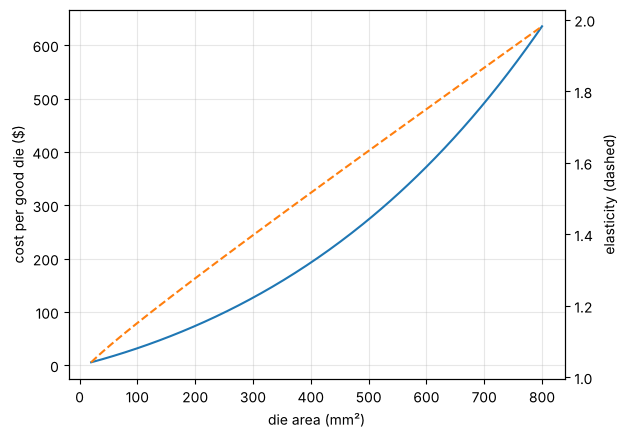

In [2]:
print(f"elasticity at 100 mm2: {tr.elasticity(100):.2f}; at 600 mm2: {tr.elasticity(600):.2f}")
A = np.linspace(20, 800, 200)
fig, ax = plt.subplots()
ax.plot(A, [tr.die_cost(a, 18500, whole=False) for a in A]); ax.set_xlabel('die area (mm²)'); ax.set_ylabel('cost per good die ($)')
ax2 = ax.twinx(); ax2.plot(A, [tr.elasticity(a) for a in A], 'C1--'); ax2.set_ylabel('elasticity (dashed)')
ax.grid(True, alpha=0.3); plt.show()

## Part 2 · Area budgets

**Predict:** the area budget on a $30,000 N2 wafer ($60 price, $8 package and test, 60% margin).

N3: 53.9 mm2; N2: 34.4 mm2


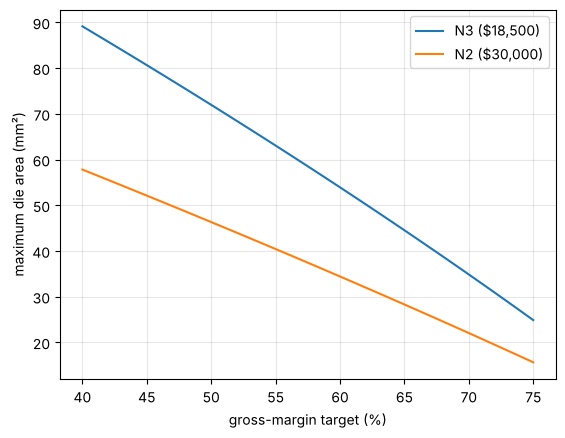

In [3]:
print(f"N3: {tr.area_budget(60, 8, 0.60, 18500):.1f} mm2; N2: {tr.area_budget(60, 8, 0.60, 30000):.1f} mm2")
g = np.linspace(0.40, 0.75, 36)
for w, lab in ((18500, 'N3 ($18,500)'), (30000, 'N2 ($30,000)')):
    plt.plot(100*g, [tr.area_budget(60, 8, x, w) for x in g], label=lab)
plt.xlabel('gross-margin target (%)'); plt.ylabel('maximum die area (mm²)'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 3 · Electricity price

**Predict:** the lifetime energy cost of a 1,000 W device at $0.15 per kWh (PUE 1.3, 4 years).

$6837


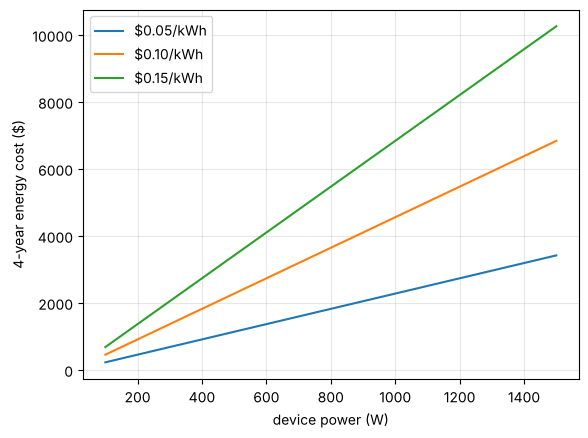

In [4]:
print(f"${tr.energy_cost(1000, 1.3, 4, 0.15):.0f}")
P = np.linspace(100, 1500, 50)
for pe in (0.05, 0.10, 0.15):
    plt.plot(P, [tr.energy_cost(p, 1.3, 4, pe) for p in P], label=f'${pe:.2f}/kWh')
plt.xlabel('device power (W)'); plt.ylabel('4-year energy cost ($)'); plt.legend(); plt.grid(True, alpha=0.3); plt.show()

## Part 4 · A big-die tornado

**Predict:** the base margin of a 600 mm² die at $900 with $80 of package and test, and the cost of a 10% rise in defect density.

100 mm² at $90: base 55.6%  asp +4.03, area -4.13, wafer -3.55, d0 -0.36, pkg -0.89
600 mm² at $900: base 49.5%  asp +4.59, area -7.48, wafer -4.16, d0 -2.57, pkg -0.89


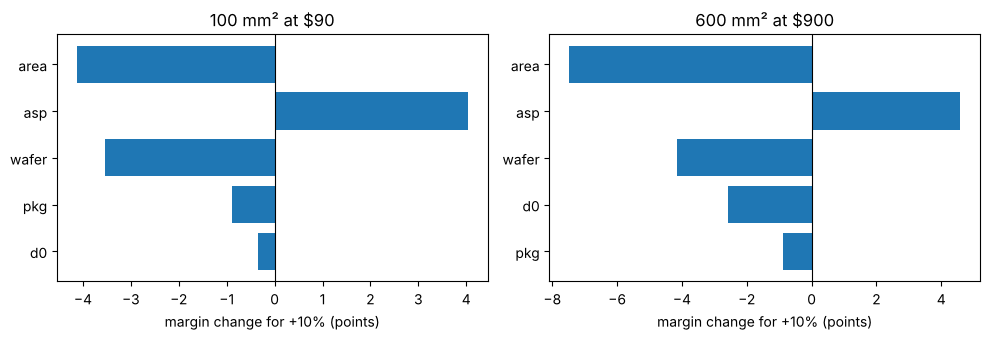

In [5]:
small = dict(asp=90, area=100, wafer=18500, d0=0.001, pkg=8)
big = dict(asp=900, area=600, wafer=18500, d0=0.001, pkg=80)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (name, base) in zip(axes, (('100 mm² at $90', small), ('600 mm² at $900', big))):
    b, t = tr.tornado(base)
    print(f"{name}: base {100*b:.1f}%  " + ", ".join(f"{k} {v:+.2f}" for k, v in t.items()))
    keys = sorted(t, key=lambda k: abs(t[k]))
    ax.barh(keys, [t[k] for k in keys]); ax.axvline(0, color='k', lw=0.8)
    ax.set_title(name); ax.set_xlabel('margin change for +10% (points)')
plt.tight_layout(); plt.show()